# Controlled 3-state 2BSDE: nonlinear drift, observation- and posterior-dependent benchmark

The dynamics, control set and time horizon are:
$$
X\in\{-1,0,1\},\qquad dY_t=(X-u_t)^2\,dt+dW_t,
\qquad u_t\in[-1,1],\qquad T=1.
$$
The hidden state $X$ is fixed but unknown. Its posterior is
$p_t^i=\mathbb P(X=\theta_i\mid\mathcal Y_t)$, with
$\theta=(-1,0,1)^\top$. The drift
$$
h(u,x)=(x-u)^2=x^2-2xu+u^2
$$
is nonlinear in both $x$ and $u$. The control also changes what can be learned:
$h(u,-1)-h(u,1)=4u$, so $u=0$ cannot distinguish the two states $-1$ and $1$.

Define
$$
m(p)=\sum_i p_i\theta_i,\qquad s(p)=\sum_i p_i\theta_i^2,
\qquad v(p)=s(p)-m(p)^2,
$$
$$
c(p)=\sum_i p_i\theta_i^3-m(p)s(p)
=m(p)(1-s(p)).
$$
Here $m$ is the posterior mean, $v$ is the posterior variance, and $c$ is
$\operatorname{Cov}_p(X,X^2)$. The last equality uses $\theta_i^3=\theta_i$.
Under the observation filtration, the coupled state satisfies
$$
dY_t=\bar h(p_t,u_t)\,dt+dI_t,\qquad
dp_t^i=\beta_i(p_t,u_t)\,dI_t,
$$
$$
\bar h(p,u)=s-2um+u^2,\qquad
\beta_i(p,u)=p_i\bigl((\theta_i-u)^2-\bar h(p,u)\bigr).
$$
The same innovation Brownian motion $I$ drives both components. The state used
by the 2BSDE is $S=(Y,p_1,p_2,p_3)$; no additional sensor noise is introduced.

Set
$$
A(y,p)=5+\tanh y-2v(p)^2,\qquad
B(y,p)=m(p)\tanh y-c(p)v(p).
$$
The running and terminal costs are
$$
k(y,p,u)=5u^2+\tfrac12\left[(\tanh y-s)^2+1-s^2+c^2\right]
+\frac{B(y,p)^2}{A(y,p)},
\qquad g(y,p)=\log\cosh y+\tfrac12v(p).
$$
We minimise
$$
J_{t,y,p}(u)=\mathbb E_{t,y,p}\left[
\int_t^T k(Y_r,p_r,u_r)\,dr+g(Y_T,p_T)\right].
$$
The terminal cost penalises displacement from $y=0$ and remaining uncertainty.
The running cost contains quadratic control effort and a state-dependent term
chosen to make the solution explicit. Since $0\le s\le1$ and $A\ge2$, both
costs are nonnegative. This is a constructed benchmark, rather than a claim
that an arbitrary tracking cost has the same solution.

The exact value and optimal feedback are
$$
\boxed{V(t,y,p)=\log\cosh y+\tfrac12v(p)+(T-t),
\qquad u^*(t,y,p)=\frac{B(y,p)}{A(y,p)}.}
$$
The feedback has no explicit time dependence, but changes along a path through
$Y_t$ and $p_t$. The functions below retain the same time arguments as the
original notebook. Since $v\le1$, $|m|\le1$ and $|c|\le1/2$,
$A\ge2$ and $|u^*|\le3/4$; the optimum needs no clipping.

For $y_0=0$, $p_0=(0.2,0.3,0.5)$,
$$
V_0=\frac{261}{200}=1.305,\qquad
u_0^*=-\frac{183}{14186}\simeq-0.01290004.
$$
We use an asymmetric prior because a symmetric prior would give $m=c=0$ and
leave this optimal feedback identically zero. The value and gradient depend
on the state. The observation-observation Hessian also depends on the state;
the posterior-posterior block is constant and the mixed block is zero.

In [1]:
from pathlib import Path
import math
import sys

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from two_bsde.config import ModelConfig, HamiltonianConfig, TrainingConfig
from two_bsde.problem import BayesianControlProblem
from two_bsde.geometry import make_simplex_tangent_basis, SimplexGeometry
from two_bsde.hamiltonian import HamiltonianOptimizer
from two_bsde.twoBsdeStructure import GeometricTimeBlockAdaptive2BSDE
from two_bsde.dynamics import split_state, state_dynamics
from two_bsde.training import train_time_blocks
from two_bsde.evaluation import evaluate_time_blocks

DTYPE = torch.float64
DEVICE = torch.device("cpu")

torch.manual_seed(42)
np.random.seed(42)

In [2]:
config = ModelConfig(
    horizon=1.0,
    hidden_dim=1,
    observation_dim=1,
    control_dim=1,
    num_hidden_states=3,
    num_time_steps=30,
    network_width=64,
    network_depth=5,
    value_initial_guess=0.01,
    gamma_initial_scale=0.01,
)

ham_config = HamiltonianConfig(
    num_starts=12,
    num_steps=30,
    learning_rate=5e-2,
)

training_config = TrainingConfig(
    epochs=3000,
    batch_size=128,
    learning_rate=1e-4,
    gradient_clip=10.0,
    value_loss_weight=1.0,
    gradient_loss_weight=1.0,
)

basis = make_simplex_tangent_basis(
    config.num_hidden_states,
    dtype=DTYPE,
    device=DEVICE,
)

geometry = SimplexGeometry(
    observation_dim=config.observation_dim,
    basis=basis,
)

print("state_dim =", config.state_dim)
print("tangent_dim =", config.tangent_dim)

state_dim = 4
tangent_dim = 2


## Concrete problem

In [3]:
class ControlledThreeStateProblem(BayesianControlProblem):
    def __init__(self, config):
        super().__init__(config)
        if config.horizon != 1.0:
            raise ValueError("This benchmark uses horizon T=1.")
        if getattr(config, "observation_noise_std", 1.0) != 1.0:
            raise ValueError("This analytic benchmark uses observation noise sigma=1.")

        self.theta = torch.tensor([-1.0, 0.0, 1.0], dtype=DTYPE, device=DEVICE)
        self.x_support = self.theta[:, None].clone()
        self.initial_observation = torch.tensor([0.0], dtype=DTYPE, device=DEVICE)
        self.initial_posterior = torch.tensor([0.20, 0.30, 0.50], dtype=DTYPE, device=DEVICE)
        self.control_low = torch.tensor([-1.0], dtype=DTYPE, device=DEVICE)
        self.control_high = torch.tensor([1.0], dtype=DTYPE, device=DEVICE)

        # Retained for compatibility with the original problem setup.
        # The time-block model instead applies each path's own minimiser.
        self.auxiliary_control_path = torch.zeros(
            config.num_time_steps, config.control_dim, dtype=DTYPE, device=DEVICE,
        )
        self.validate(config)

    def sensor(self, control, observation):
        lead_shape = control.shape[:-1]
        theta = self.theta.to(control).reshape(
            *([1] * len(lead_shape)), self.config.num_hidden_states, 1,
        )
        # [..., 3, 1], including separate path and candidate-control axes.
        return (theta - control.unsqueeze(-2)).square()

    @staticmethod
    def log_cosh(y):
        # Stable at large |y| and twice differentiable at y=0.
        return torch.logaddexp(y, -y) - math.log(2.0)

    def posterior_terms(self, state):
        p = state[..., self.config.observation_dim:]
        theta = self.theta.to(state)
        m = (p * theta).sum(dim=-1)
        s = (p * theta.square()).sum(dim=-1)
        v = s - m.square()
        c = (p * theta.pow(3)).sum(dim=-1) - m * s
        return m, s, v, c

    def hamiltonian_terms(self, state):
        m, _, v, c = self.posterior_terms(state)
        tanh_y = torch.tanh(state[..., 0])
        A = 5.0 + tanh_y - 2.0 * v.square()
        B = m * tanh_y - c * v
        return A, B

    def running_cost(self, state, control, *, time=None):
        # This example is autonomous; retain time for the package interface.
        _, s, _, c = self.posterior_terms(state)
        tanh_y, u = torch.tanh(state[..., 0]), control[..., 0]
        A, B = self.hamiltonian_terms(state)
        return (
            5.0 * u.square()
            + 0.5 * ((tanh_y - s).square() + 1.0 - s.square() + c.square())
            + B.square() / A
        )

    def terminal_cost(self, state):
        _, _, v, _ = self.posterior_terms(state)
        return self.log_cosh(state[..., 0]) + 0.5 * v


problem = ControlledThreeStateProblem(config)
S0 = torch.cat((problem.initial_observation, problem.initial_posterior))
print("S0 =", S0)
print("theta =", problem.theta)
print("Control: each path uses its own Hamiltonian minimiser at every fine step.")

S0 = tensor([0.0000, 0.2000, 0.3000, 0.5000], dtype=torch.float64)
theta = tensor([-1.,  0.,  1.], dtype=torch.float64)
Control: each path uses its own Hamiltonian minimiser at every fine step.


## Analytic solution

The derivatives below use the posterior tangent projection
$P=I-\mathbf 1\mathbf 1^\top/3$. With $\theta=(-1,0,1)^\top$ and
$\theta^{\circ2}=(1,0,1)^\top$,
$$
Z_y=\tanh y,\qquad
Z_p=P\left(\tfrac12\theta^{\circ2}-m\theta\right)
=\left(m+\tfrac16,-\tfrac13,\tfrac16-m\right)^\top,
$$
$$
\Gamma_{yy}=\operatorname{sech}^2y=1-\tanh^2y,\qquad
\Gamma_{yp}=0,\qquad
\Gamma_{pp}=-P\theta\theta^\top P=-\theta\theta^\top.
$$
Here $Z$ denotes the state gradient in the package's convention. These formulas
follow from $v(p)=s(p)-m(p)^2$: its ambient gradient is
$\theta^{\circ2}-2m\theta$ and its Hessian is $-2\theta\theta^\top$.
In particular, the posterior Hessian of $V$ is $-\theta\theta^\top$, not $-P$.

The mixed block is zero because $V$ is additive in $y$ and $p$, even though
$Y$ and $p$ share the same Brownian motion. The full Hessian contraction is
still used below. At $T$, the same gradient and Hessian are those of $g$.

In [4]:
def exact_value(time, state):
    time = torch.as_tensor(time, dtype=state.dtype, device=state.device)
    return problem.terminal_cost(state) + config.horizon - time


def exact_gradient(time, state):
    m, _, _, _ = problem.posterior_terms(state)
    theta = problem.theta.to(state)
    ambient = torch.zeros_like(state)
    ambient[..., 0] = torch.tanh(state[..., 0])
    ambient[..., config.observation_dim:] = (
        0.5 * theta.square() - m[..., None] * theta
    )
    return geometry.project_gradient(ambient)


def exact_hessian(time, state):
    theta = problem.theta.to(state)
    shape = state.shape[:-1] + (config.state_dim, config.state_dim)
    gamma = torch.zeros(shape, dtype=state.dtype, device=state.device)
    gamma[..., 0, 0] = 1.0 - torch.tanh(state[..., 0]).square()
    # theta already lies in the posterior tangent space: P @ theta = theta.
    gamma[..., config.observation_dim:, config.observation_dim:] = (
        -torch.outer(theta, theta)
    )
    return gamma


def exact_control(time, state):
    A, B = problem.hamiltonian_terms(state)
    return (B / A).unsqueeze(-1)


V0_exact = exact_value(0.0, S0)
u0_exact = exact_control(0.0, S0)
print("exact V0 =", V0_exact.item())
print("exact u0* =", u0_exact.item())
assert abs(V0_exact.item() - 261.0 / 200.0) < 1e-12
assert abs(u0_exact.item() + 183.0 / 14186.0) < 1e-12

exact V0 = 1.305
exact u0* = -0.01290004229522064


## Verify the analytic HJB

The posterior mean satisfies
$$
dm_t=(c_t-2u_tv_t)\,dI_t.
$$
Since $s_t$ is a martingale, Itô's formula for $v_t=s_t-m_t^2$ gives
$$
dv_t=\text{martingale term}-(c_t-2u_tv_t)^2\,dt.
$$
Consequently,
$$
\mathcal L^u V
=\tanh y\,(s-2um+u^2)
+\tfrac12\operatorname{sech}^2y
-\tfrac12(c-2uv)^2.
$$
Using $\partial_tV=-1$ and $\operatorname{sech}^2y=1-\tanh^2y$, the terms
independent of $u$ cancel against the chosen running cost, leaving
$$
\partial_tV+\mathcal L^uV+k
=Au^2-2Bu+\frac{B^2}{A}
=A\left(u-u^*(y,p)\right)^2.
$$
As $A>0$ and $u^*\in[-1,1]$, the HJB minimum is zero and is attained at
$u^*=B/A$. Also $V(T,y,p)=g(y,p)$. Applying Itô's formula and taking
expectations yields the verification identity
$$
J_{t,y,p}(u)-V(t,y,p)
=\mathbb E_{t,y,p}\int_t^T
A(Y_r,p_r)\left(u_r-u^*(Y_r,p_r)\right)^2\,dr\ge0.
$$
The coefficients and derivatives in this identity are bounded, so the stochastic
integral has zero expectation. Equality holds for the displayed feedback.

The checks below use the package dynamics and the full Hessian. They verify
the identity for several states, times and controls, the terminal condition,
and the analytic derivatives against autograd.

In [5]:
def analytic_hjb_expression(time, state, control):
    drift, sigma, _ = state_dynamics(
        state, control, problem=problem, config=config, geometry=geometry,
    )
    time_derivative = -torch.ones_like(state[..., 0])
    running = problem.running_cost(state, control, time=time)
    z = exact_gradient(time, state)
    gamma = exact_hessian(time, state)
    first_order = (drift * z).sum(dim=-1)
    # Full contraction; the analytic mixed block happens to be zero here.
    second_order = 0.5 * torch.einsum("...ia,...ij,...ja->...", sigma, gamma, sigma)
    return time_derivative + running + first_order + second_order


test_states = torch.tensor(
    [[0.0, 0.20, 0.30, 0.50],
     [0.4, 0.70, 0.20, 0.10],
     [-0.6, 0.05, 0.20, 0.75]],
    dtype=DTYPE, device=DEVICE,
)

for time in [0.0, 0.25, 0.5, 0.9, 1.0]:
    u_exact = exact_control(time, test_states)
    hjb_at_exact = analytic_hjb_expression(time, test_states, u_exact)
    print(f"t={time:.2f}: analytic control = {u_exact[:, 0].cpu().numpy()}")
    print("         HJB at analytic control =", hjb_at_exact.cpu().numpy())
    assert torch.allclose(hjb_at_exact, torch.zeros_like(hjb_at_exact), atol=1e-12)

    A, _ = problem.hamiltonian_terms(test_states)
    assert torch.all(A >= 2.0)
    assert torch.all(u_exact.abs() <= 0.75 + 1e-12)
    for u_value in [-1.0, -0.5, 0.0, 0.5, 1.0]:
        u = torch.full((len(test_states), 1), u_value, dtype=DTYPE, device=DEVICE)
        residual = analytic_hjb_expression(time, test_states, u)
        square = A * (u[:, 0] - u_exact[:, 0]).square()
        assert torch.allclose(residual, square, atol=1e-12)
        assert torch.all(residual >= -1e-12)
        assert torch.all(problem.running_cost(test_states, u, time=time) >= -1e-12)

assert torch.allclose(exact_value(1.0, test_states), problem.terminal_cost(test_states))
assert torch.allclose(
    exact_gradient(1.0, test_states),
    geometry.project_gradient(problem.terminal_gradient(test_states)),
)
for state in test_states:
    gradient_ad = torch.autograd.functional.jacobian(problem.terminal_cost, state)
    hessian_ad = torch.autograd.functional.hessian(problem.terminal_cost, state)
    assert torch.allclose(exact_gradient(1.0, state), geometry.project_gradient(gradient_ad), atol=1e-12)
    assert torch.allclose(exact_hessian(1.0, state), geometry.project_hessian(hessian_ad), atol=1e-12)
print("analytic HJB, terminal and derivative checks: PASSED")

t=0.00: analytic control = [-0.01290004 -0.03508476 -0.09818759]
         HJB at analytic control = [-5.55111512e-17  1.11022302e-16  1.11022302e-16]
t=0.25: analytic control = [-0.01290004 -0.03508476 -0.09818759]
         HJB at analytic control = [-5.55111512e-17  1.11022302e-16  1.11022302e-16]
t=0.50: analytic control = [-0.01290004 -0.03508476 -0.09818759]
         HJB at analytic control = [-5.55111512e-17  1.11022302e-16  1.11022302e-16]
t=0.90: analytic control = [-0.01290004 -0.03508476 -0.09818759]
         HJB at analytic control = [-5.55111512e-17  1.11022302e-16  1.11022302e-16]
t=1.00: analytic control = [-0.01290004 -0.03508476 -0.09818759]
         HJB at analytic control = [-5.55111512e-17  1.11022302e-16  1.11022302e-16]
analytic HJB, terminal and derivative checks: PASSED


## Build the time-block 2BSDE model

Use the same 3 shared blocks and 30 fine time steps. All paths start from the
initial state above. Each path applies its own fine-step Hamiltonian minimiser.

In [6]:
hamiltonian_optimizer = HamiltonianOptimizer(
    problem=problem,
    model_config=config,
    optimizer_config=ham_config,
    geometry=geometry,
)

model = GeometricTimeBlockAdaptive2BSDE(
    problem=problem,
    config=config,
    geometry=geometry,
    hamiltonian_optimizer=hamiltonian_optimizer,
    num_blocks=3,
).to(device=DEVICE, dtype=DTYPE)

print("number of time blocks =", model.num_blocks)


number of time blocks = 3


## Train the time-block 2BSDE


In [7]:
history = train_time_blocks(
    model,
    training_config=training_config,
    sample_start_times=False,  # start at t=0, as in the original notebook
    # boundary_weight=0.0,     # uncomment to disable the boundary penalty
    verbose=True,
)

epoch=   1  start_step=  0  total_loss=2.494e+00  terminal_value=2.202e+00  terminal_gradient=2.073e-01  consistency=8.482e-02  boundary=2.256e-04  mean_start_value=0.013107
epoch= 300  start_step=  0  total_loss=1.130e-01  terminal_value=4.792e-02  terminal_gradient=3.912e-03  consistency=5.696e-02  boundary=4.196e-02  mean_start_value=1.297166
epoch= 600  start_step=  0  total_loss=5.505e-02  terminal_value=2.577e-02  terminal_gradient=2.006e-03  consistency=2.260e-02  boundary=4.669e-02  mean_start_value=1.301696
epoch= 900  start_step=  0  total_loss=3.320e-02  terminal_value=1.708e-02  terminal_gradient=2.242e-03  consistency=1.186e-02  boundary=2.024e-02  mean_start_value=1.303794
epoch=1200  start_step=  0  total_loss=2.337e-02  terminal_value=9.519e-03  terminal_gradient=1.327e-03  consistency=1.101e-02  boundary=1.512e-02  mean_start_value=1.304382
epoch=1500  start_step=  0  total_loss=2.507e-02  terminal_value=1.314e-02  terminal_gradient=1.121e-03  consistency=9.060e-03  bo

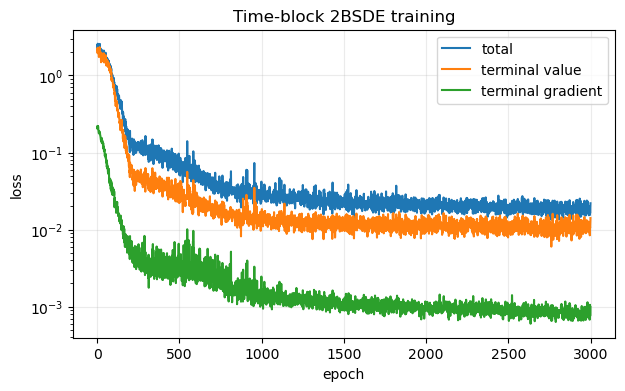

In [8]:
plt.figure(figsize=(7, 4))
plt.semilogy(history.total_loss, label="total")
plt.semilogy(history.terminal_value_loss, label="terminal value")
plt.semilogy(history.terminal_gradient_loss, label="terminal gradient")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Time-block 2BSDE training")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## Compare the learned initial value with the analytic solution


In [9]:
with torch.no_grad():
    V0_learned = model.value(0.0, S0)

print("VALUE")
print(" learned:", V0_learned.item())
print(" exact:  ", V0_exact.item())
print(" abs err:", abs(V0_learned.item() - V0_exact.item()))


VALUE
 learned: 1.3051227370539975
 exact:   1.305
 abs err: 0.00012273705399756807


## Test the inner Hamiltonian optimizer with the analytic derivatives

Test several posteriors and times. For scalar controls the optimizer searches
a uniform grid, so compare with the continuous analytic optimum using half the
grid spacing as the tolerance. This separates the control-search discretisation
from errors in the learned $Z$ and $\Gamma$.

In [10]:
state_batch = torch.tensor(
    [[0.0, 0.20, 0.30, 0.50],
     [0.2, 0.10, 0.20, 0.70],
     [-0.3, 0.65, 0.25, 0.10]],
    dtype=DTYPE, device=DEVICE,
)

grid_size = max(81, 20 * ham_config.num_starts + 1)
grid_spacing = (problem.control_high - problem.control_low).item() / (grid_size - 1)
print("control-grid spacing =", grid_spacing)
print("exact-derivative tolerance =", 0.5 * grid_spacing)

with torch.no_grad():
    for time in [0.0, 0.25, 0.5, 0.9]:
        _, u_from_exact_derivatives = hamiltonian_optimizer.minimise(
            state_batch,
            exact_gradient(time, state_batch),
            exact_hessian(time, state_batch),
            time=time,
        )
        u_analytic = exact_control(time, state_batch)
        error = (u_from_exact_derivatives - u_analytic).abs().max().item()
        print(f"t={time:.2f}")
        print(" numerical u* =", u_from_exact_derivatives[:, 0].cpu().numpy())
        print(" analytic  u* =", u_analytic[:, 0].cpu().numpy())
        print(" max abs error =", error)
        assert error <= 0.5 * grid_spacing + 1e-10

control-grid spacing = 0.008333333333333333
exact-derivative tolerance = 0.004166666666666667
t=0.00
 numerical u* = [-0.01666667  0.01666667  0.05      ]
 analytic  u* = [-0.01290004  0.01364299  0.05147265]
 max abs error = 0.0037666243714460403
t=0.25
 numerical u* = [-0.01666667  0.01666667  0.05      ]
 analytic  u* = [-0.01290004  0.01364299  0.05147265]
 max abs error = 0.0037666243714460403
t=0.50
 numerical u* = [-0.01666667  0.01666667  0.05      ]
 analytic  u* = [-0.01290004  0.01364299  0.05147265]
 max abs error = 0.0037666243714460403
t=0.90
 numerical u* = [-0.01666667  0.01666667  0.05      ]
 analytic  u* = [-0.01290004  0.01364299  0.05147265]
 max abs error = 0.0037666243714460403


## Fresh-path 2BSDE evaluation: paired analytic comparisons

For each simulated numerical state $S_k^{(b)}=(Y_k^{(b)},p_k^{(b)})$, compare
$$
u_k^{\mathrm{num},(b)}\quad\hbox{with}\quad
u^*(t_k,Y_k^{(b)},p_k^{(b)}).
$$
The analytic feedback is evaluated at **the same observation, posterior and time**,
so no independent analytic trajectory is needed. Controls and Hessians use the
state at the **start** of each step; value and gradient paths also include $T$.

We report paired MAE and RMSE, alongside individual paired paths and ensemble
summaries. The analytic 10–90% band measures variation across paths, not a
confidence interval. Its two edges are plotted explicitly and the vertical
axis is allowed to autoscale. The exact control can be negative or cross zero,
so we use absolute errors rather than relative errors.

The analytic reference is exact for the continuous-time problem; the numerical
state paths use the existing Euler scheme and posterior stabilisation.

In [11]:
result = evaluate_time_blocks(model, num_paths=500, evaluate_policy=False)
paths = result.paths

with torch.no_grad():
    times = paths["time_path"]                    # [steps+1]
    control_times = times[:-1]                    # [steps]
    states = paths["S_path"]                      # [paths, steps+1, state_dim]
    u_star_path = paths["u_star_path"][..., 0]    # [paths, steps]
    u_exact_path = exact_control(control_times, states[:, :-1])[..., 0]
    control_error = u_star_path - u_exact_path
    mean_u_by_time = u_star_path.mean(dim=0)
    mean_exact_u_by_time = u_exact_path.mean(dim=0)
    mae_u_by_time = control_error.abs().mean(dim=0)
    rmse_u_by_time = control_error.square().mean(dim=0).sqrt()
    q10_exact, q90_exact = torch.quantile(
        u_exact_path, torch.tensor([0.1, 0.9], dtype=DTYPE, device=DEVICE), dim=0,
    )

    V_exact_path = exact_value(times, states)
    value_head_error = paths["value_path"] - V_exact_path
    propagated_value_error = paths["R_path"] - V_exact_path

assert torch.equal(paths["u_aux_path"], paths["u_star_path"])
print("PAIRED CONTROL COMPARISON AT THE SAME STATES")
print(" mean absolute error =", control_error.abs().mean().item())
print(" root mean square error =", control_error.square().mean().sqrt().item())
print(" maximum absolute error =", control_error.abs().max().item())
print(" maximum analytic 10-90% band width =", (q90_exact - q10_exact).max().item())
print("PAIRED VALUE COMPARISON AT THE SAME STATES")
print(" value-network RMSE =", value_head_error.square().mean().sqrt().item())
print(" propagated R RMSE  =", propagated_value_error.square().mean().sqrt().item())
print(" posterior correction rate =", result.diagnostics["posterior_correction_rate"])

PAIRED CONTROL COMPARISON AT THE SAME STATES
 mean absolute error = 0.014805463188999253
 root mean square error = 0.01673262614760569
 maximum absolute error = 0.036927220172331514
 maximum analytic 10-90% band width = 0.09596126816170449
PAIRED VALUE COMPARISON AT THE SAME STATES
 value-network RMSE = 0.07811383135976747
 propagated R RMSE  = 0.0745556394509272
 posterior correction rate = 0.0


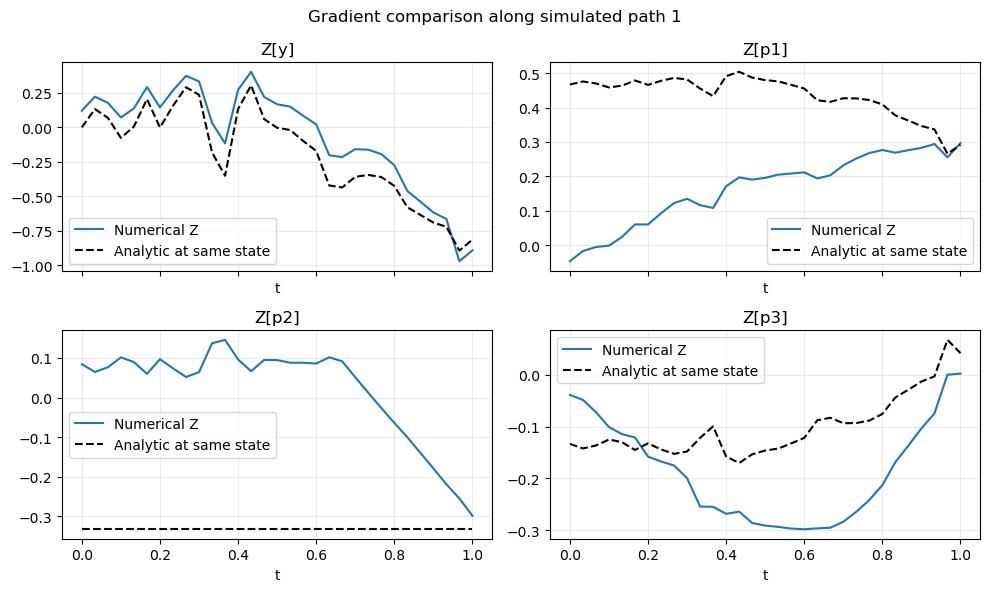

In [12]:
path_id = 1

with torch.no_grad():
    Z_learned = paths["Z_path"][path_id].detach().cpu()
    Z_exact = exact_gradient(times, states[path_id]).detach().cpu()

time_numpy = times.detach().cpu().numpy()
labels = ["y", "p1", "p2", "p3"]
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(time_numpy, Z_learned[:, i].numpy(), label="Numerical Z")
    ax.plot(time_numpy, Z_exact[:, i].numpy(), "--", color="black", label="Analytic at same state")
    ax.set_title(f"Z[{labels[i]}]")
    ax.set_xlabel("t")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f"Gradient comparison along simulated path {path_id}")
plt.tight_layout()
plt.show()

In [13]:
with torch.no_grad():
    Gamma0_learned = model.blocks[0].gamma(0.0, S0)
    Gamma0_exact = exact_hessian(0.0, S0)

print("HESSIAN AT t=0")
print(" learned:\n", Gamma0_learned)
print(" exact:\n", Gamma0_exact)
print(" Frobenius error:", torch.linalg.matrix_norm(Gamma0_learned - Gamma0_exact, ord="fro").item())

HESSIAN AT t=0
 learned:
 tensor([[ 0.6570,  0.0133, -0.2572,  0.2439],
        [ 0.0133,  0.0750, -0.2426,  0.1676],
        [-0.2572, -0.2426, -0.2339,  0.4765],
        [ 0.2439,  0.1676,  0.4765, -0.6441]], dtype=torch.float64)
 exact:
 tensor([[ 1.,  0.,  0.,  0.],
        [ 0., -1.,  0.,  1.],
        [ 0.,  0., -0., -0.],
        [ 0.,  1., -0., -1.]], dtype=torch.float64)
 Frobenius error: 1.9140873119816835


Mean Hessian error: 1.8161475533621458


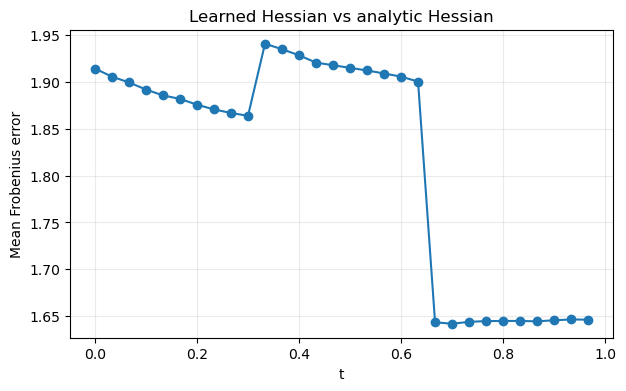

In [14]:
with torch.no_grad():
    # Gamma at step k belongs to the state at the START of that step.
    Gamma_learned = paths["Gamma_path"]           # [paths, steps, 4, 4]
    Gamma_exact = exact_hessian(control_times, states[:, :-1])
    error = torch.linalg.matrix_norm(
        Gamma_learned - Gamma_exact, ord="fro", dim=(-2, -1),
    )                                           # [paths, steps]

print("Mean Hessian error:", error.mean().item())
plt.figure(figsize=(7, 4))
plt.plot(control_times.cpu().numpy(), error.mean(dim=0).cpu().numpy(), marker="o")
plt.xlabel("t")
plt.ylabel("Mean Frobenius error")
plt.title("Learned Hessian vs analytic Hessian")
plt.grid(alpha=0.25)
plt.show()

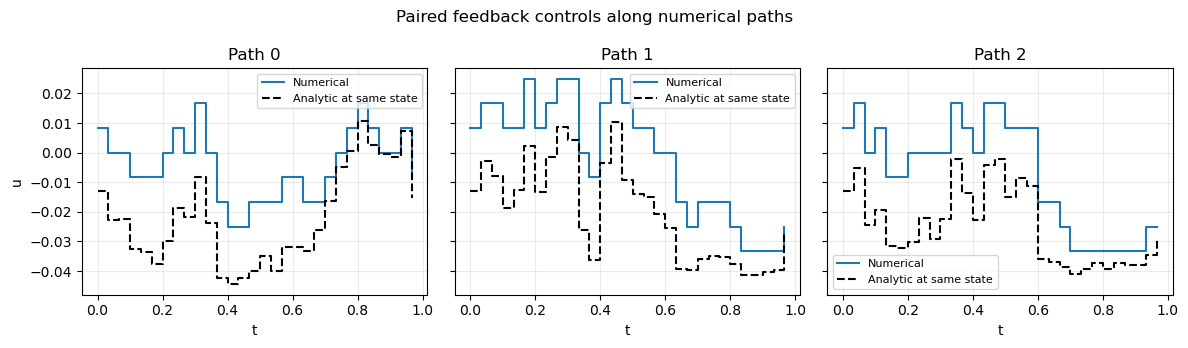

In [15]:
time_grid = control_times.detach().cpu().numpy()

# Individual paired paths show differences hidden by ensemble means.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True, sharey=True)
for path_id, ax in enumerate(axes):
    ax.step(time_grid, u_star_path[path_id].cpu().numpy(), where="post", label="Numerical")
    ax.step(time_grid, u_exact_path[path_id].cpu().numpy(), where="post", linestyle="--",
            color="black", label="Analytic at same state")
    ax.set_title(f"Path {path_id}")
    ax.set_xlabel("t")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel("u")
fig.suptitle("Paired feedback controls along numerical paths")
plt.tight_layout()
plt.show()

Ensemble, 500 simulated paths, 
$$
    \operatorname{MAE}(t)=\frac{1}{N} \sum_{i=1}^N\left|e_i\right|.
$$
$$
    \operatorname{RMSE}(t)=\sqrt{\frac{1}{N} \sum_{i=1}^N e_i^2}.
$$

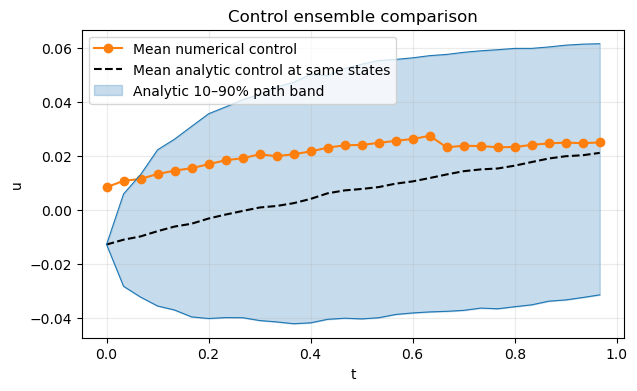

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(time_grid, mean_u_by_time.cpu().numpy(), marker="o", color="tab:orange",
         label="Mean numerical control")
plt.plot(time_grid, mean_exact_u_by_time.cpu().numpy(), "--", color="black",
         label="Mean analytic control at same states")
plt.fill_between(time_grid, q10_exact.cpu().numpy(), q90_exact.cpu().numpy(),
                 color="tab:blue", alpha=0.25, label="Analytic 10–90% path band")
plt.plot(time_grid, q10_exact.cpu().numpy(), color="tab:blue", linewidth=0.8)
plt.plot(time_grid, q90_exact.cpu().numpy(), color="tab:blue", linewidth=0.8)
plt.xlabel("t")
plt.ylabel("u")
plt.title("Control ensemble comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

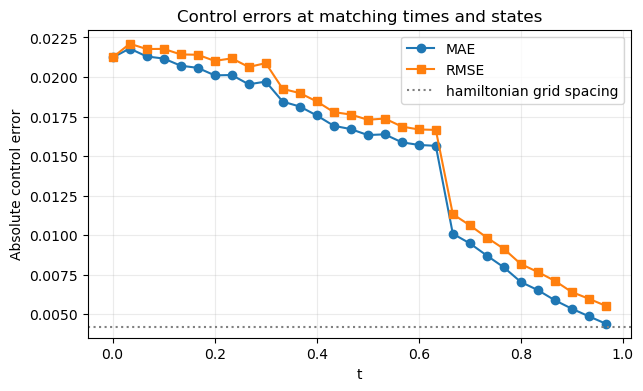

In [18]:
plt.figure(figsize=(7, 4))
plt.plot(time_grid, mae_u_by_time.cpu().numpy(), marker="o", label="MAE")
plt.plot(time_grid, rmse_u_by_time.cpu().numpy(), marker="s", label="RMSE")
plt.axhline(0.5 * grid_spacing, color="gray", linestyle=":",
            label="hamiltonian grid spacing")
plt.xlabel("t")
plt.ylabel("Absolute control error")
plt.title("Control errors at matching times and states")
plt.legend()
plt.grid(alpha=0.25)
plt.show()